# BANKING77 with Qwen models of increasing size

How much does model size matter for a simple, well-defined task? We classify customer
queries from the **BANKING77** test set (3,080 queries, 77 fine-grained intents) **zero-shot** with
Qwen models of increasing size, served locally with **Ollama**.

* The label set is enforced with Ollama's *structured outputs* (JSON schema with an `enum`), so every
  answer is a valid intent and we measure classification quality rather than format compliance.
* Thinking mode is off (`think=False`) and decoding is greedy (`temperature=0`).
* Predictions are cached in `results/banking77/structured_no-think/<model>.jsonl`, so re-running a cell resumes
  instead of recomputing. The same pipeline is available as a script: `scripts/run_banking77.py`.

In [1]:
import pandas as pd
import matplotlib.pyplot as plt

from slm import RESULTS_DIR
from slm.data import load_banking77
from slm.evaluation import LLMClassifier, evaluate, score, stratified_subset
from slm.evaluation.classification import INVALID
from slm.inference import OllamaBackend, params_in_billions

pd.set_option("display.max_colwidth", 120)

/home/phth01/PycharmProjects/small-language-models/.venv/lib/python3.12/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


## 1. Data

In [2]:
dataset = load_banking77()
print(f"train={len(dataset.train)}  test={len(dataset.test)}  labels={len(dataset.labels)}")
dataset.test.sample(8, random_state=0)

train=10003  test=3080  labels=77


,text,label
2000,Can I verify the source of my funds?,verify_source_of_funds
2668,What's the deal? My card was just denied for top up. Why is it not going through?,top_up_failed
1998,I made a payment that got charged twice instead of once.,transaction_charged_twice
2465,How can I top up with this cheque I got?,top_up_by_cash_or_cheque
1051,"When I deposit cheques and cash, my balance does not update.",balance_not_updated_after_cheque_or_cash_deposit
2060,How long do I have to wait for a transfer from the US?,transfer_timing
1199,Why did I need to verfiy my identity?,why_verify_identity
1900,"This company isn't good, I would like to delete my account.",terminate_account


In [3]:
dataset.test["label"].value_counts().describe()  # the test set is (almost) balanced: 40 queries per intent

count    77.0
mean     40.0
std       0.0
min      40.0
25%      40.0
50%      40.0
75%      40.0
max      40.0
Name: count, dtype: float64

## 2. The classifier

A single system prompt lists all 77 intents; the user message is the query. Because the system prompt
is identical for every request, Ollama can reuse its KV cache across queries.

In [4]:
clf = LLMClassifier(OllamaBackend("qwen3.5:0.8b"), dataset.labels)
print(clf.system_prompt[:600], "...")

You are an intent classifier for customer messages sent to a bank.
Assign the message to exactly one of the following intents:

- card_arrival
- card_linking
- exchange_rate
- card_payment_wrong_exchange_rate
- extra_charge_on_statement
- pending_cash_withdrawal
- fiat_currency_support
- card_delivery_estimate
- automatic_top_up
- card_not_working
- exchange_via_app
- lost_or_stolen_card
- age_limit
- pin_blocked
- contactless_not_working
- top_up_by_bank_transfer_charge
- pending_top_up
- cancel_transfer
- top_up_limits
- wrong_amount_of_cash_received
- card_payment_fee_charged
- transfer_not ...


In [5]:
example = dataset.test.iloc[0]
print("query:", example.text)
print("gold: ", example.label)
clf.predict(example.text)

query: How do I locate my card?
gold:  card_arrival


{'prediction': 'get_physical_card',
 'prediction_lenient': 'get_physical_card',
 'raw': '{"label": "get_physical_card"}',
 'latency_s': 0.5481849900024827,
 'prompt_tokens': 516,
 'completion_tokens': 9,
 'done_reason': 'stop'}

## 3. Run the size ladder

Qwen3.5 comes in 0.8B, 2B, 4B, 9B, 27B (dense). On an 8 GB GPU the 9B model (Q4) still fits; larger
models are partly offloaded to CPU. As a reference point we add Qwen3.6-35B-A3B, a mixture-of-experts
model with 35B total but only 3B active parameters per token (plotted at its total size). Set `PER_CLASS` to an integer for a quick
run on a balanced subset (that many queries per intent).

In [6]:
MODELS = ["qwen3.5:0.8b", "qwen3.5:2b", "qwen3.5:4b", "qwen3.5:9b", "qwen3.6:35b-a3b"]
# Other ladders to compare: ["qwen3:0.6b", "qwen3:1.7b", "qwen3:4b", "qwen3:8b"]
PER_CLASS = None  # e.g. 5 for a quick run (385 queries)
WORKERS = 4

test = dataset.test if PER_CLASS is None else stratified_subset(dataset.test, PER_CLASS)
run_dir = RESULTS_DIR / "banking77" / "structured_no-think"

results, rows = {}, []
for model in MODELS:
    clf = LLMClassifier(OllamaBackend(model), dataset.labels)
    results[model] = evaluate(clf, test, cache_file=run_dir / f"{model.replace(':', '_')}.jsonl", workers=WORKERS)
    rows.append({"model": model, "params_b": params_in_billions(model), **score(results[model])})

summary = pd.DataFrame(rows)
summary.style.format({"accuracy": "{:.3f}", "macro_f1": "{:.3f}", "invalid_rate": "{:.1%}",
                      "mean_latency_s": "{:.3f}", "p95_latency_s": "{:.3f}", "mean_prompt_tokens": "{:.0f}"})

qwen3.5:0.8b: 0it [00:00, ?it/s]

qwen3.5:0.8b: 0it [00:00, ?it/s]

qwen3.5:2b: 0it [00:00, ?it/s]

qwen3.5:2b: 0it [00:00, ?it/s]

qwen3.5:4b: 0it [00:00, ?it/s]

...

qwen3.5:9b: 0it [00:00, ?it/s]

qwen3.5:9b: 0it [00:00, ?it/s]

qwen3.6:35b-a3b: 0it [00:00, ?it/s]

qwen3.6:35b-a3b: 0it [00:00, ?it/s]

,model,params_b,n,accuracy,macro_f1,invalid_rate,accuracy_lenient,invalid_rate_lenient,mean_latency_s,p95_latency_s,mean_prompt_tokens,mean_completion_tokens
0,qwen3.5:0.8b,0.800000,3080,0.460,0.420,0.0%,0.459740,0.000000,0.716,0.846,522,9.806494
1,qwen3.5:2b,2.000000,3080,0.520,0.499,0.0%,0.519805,0.000000,1.242,1.462,522,12.048052
2,qwen3.5:4b,4.000000,3080,0.686,0.669,0.0%,0.685714,0.000000,2.512,2.760,522,9.856169
3,qwen3.5:9b,9.000000,3080,0.717,0.699,0.0%,0.716558,0.000000,4.613,4.883,522,9.774026
4,qwen3.6:35b-a3b,35.000000,3080,0.761,0.755,0.0%,0.761364,0.000000,11.055,11.734,522,10.677597


## 4. Quality and cost vs. model size

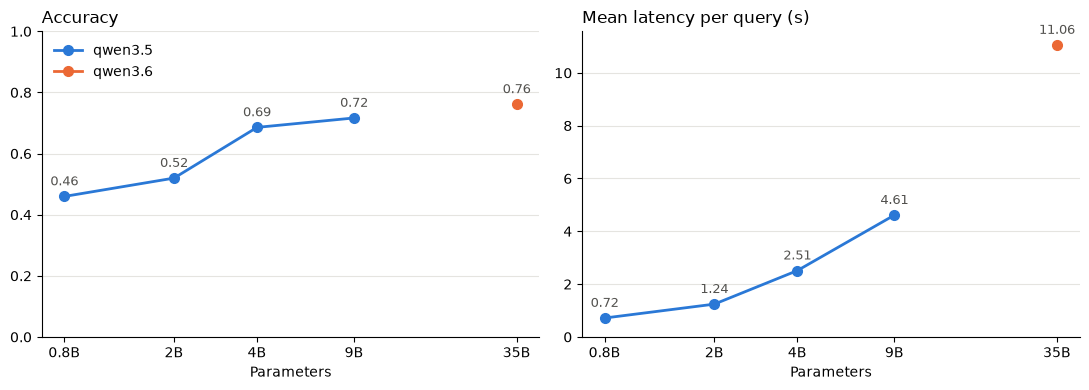

In [7]:
summary["family"] = summary["model"].str.split(":").str[0]
COLORS = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100"]  # fixed categorical order, one per model family

fig, axes = plt.subplots(1, 2, figsize=(11, 4))
panels = [("accuracy", "Accuracy"), ("mean_latency_s", "Mean latency per query (s)")]
for ax, (col, title) in zip(axes, panels):
    for color, (family, grp) in zip(COLORS, summary.groupby("family", sort=False)):
        grp = grp.sort_values("params_b")
        ax.plot(grp["params_b"], grp[col], marker="o", markersize=7, linewidth=2, color=color, label=family)
        for _, r in grp.iterrows():
            ax.annotate(f"{r[col]:.2f}", (r["params_b"], r[col]), textcoords="offset points",
                        xytext=(0, 8), ha="center", fontsize=9, color="#52514e")
    ax.set_xscale("log")
    ax.set_xticks(summary["params_b"].unique(), [f"{p:g}B" for p in summary["params_b"].unique()])
    ax.minorticks_off()
    ax.set_xlabel("Parameters")
    ax.set_title(title, loc="left")
    ax.grid(axis="y", color="#e5e4e0", linewidth=0.8)
    ax.spines[["top", "right"]].set_visible(False)
axes[0].set_ylim(0, 1)
axes[1].set_ylim(bottom=0)
axes[0].legend(frameon=False)
fig.tight_layout()

## 5. Error analysis

Which intents does the largest model confuse? Many BANKING77 intents are near-duplicates
(e.g. `card_arrival` vs. `card_delivery_estimate`), so errors cluster on such pairs.

In [8]:
largest = summary.sort_values("params_b").iloc[-1]["model"]
res = results[largest]
errors = res[res["label"] != res["prediction"]]
print(f"{largest}: {len(errors)} errors, {(res['prediction'] == INVALID).sum()} invalid")
errors.groupby(["label", "prediction"]).size().sort_values(ascending=False).head(15).rename("count").to_frame()

qwen3.6:35b-a3b: 735 errors, 0 invalid


,,count
label,prediction,
card_arrival,card_delivery_estimate,29
exchange_via_app,exchange_rate,19
get_physical_card,change_pin,19
balance_not_updated_after_bank_transfer,pending_transfer,16
beneficiary_not_allowed,failed_transfer,16
card_payment_not_recognised,compromised_card,16
verify_my_identity,why_verify_identity,15
order_physical_card,get_physical_card,14
getting_spare_card,order_physical_card,14


In [9]:
per_class = (res.assign(correct=res["label"] == res["prediction"])
               .groupby("label")["correct"].mean().sort_values())
per_class.head(10).rename("accuracy").to_frame()  # hardest intents

,accuracy
label,
get_physical_card,0.075
card_arrival,0.225
top_up_by_bank_transfer_charge,0.225
balance_not_updated_after_bank_transfer,0.300
beneficiary_not_allowed,0.325
getting_spare_card,0.325
exchange_via_app,0.350
topping_up_by_card,0.400
order_physical_card,0.400


In [10]:
errors[["text", "label", "prediction"]].sample(min(10, len(errors)), random_state=0)

,text,label,prediction
880,"To add money to my account, what currencies can I use?",supported_cards_and_currencies,fiat_currency_support
867,I made a transaction and it is taking a very long time to go through.,transfer_not_received_by_recipient,pending_transfer
21,Status of the card I ordered.,card_arrival,card_delivery_estimate
41,I would like to reactivate my card.,card_linking,activate_my_card
1698,"I am unhappy with my purchase, how do I cancel the order?",request_refund,cancel_transfer
1340,Is there a way to transfer funds directly from my card?,topping_up_by_card,transfer_into_account
1275,What do I need to do for a PIN?,get_physical_card,change_pin
3009,Are there any documents needed for the identity check?,verify_my_identity,why_verify_identity
2162,I am not able to do a transfer to an account,beneficiary_not_allowed,failed_transfer
36,"I'm starting to think my card is lost because it still hasn't arrived, can you help?",card_arrival,lost_or_stolen_card
